# Analyse de la dépense publique par secteur d'activité et dépendance financière des entreprises (2024–2026)

_Projet Python pour la Data Science — [Prénom Nom 1, Prénom Nom 2, Prénom Nom 3] — 2026._

## Introduction et contexte

La commande publique — qui regroupe les marchés publics, les accords-cadres et les concessions passés par l'État, les collectivités territoriales, les hôpitaux et les établissements publics — représente un levier économique majeur en France. Au-delà de sa fonction première d'approvisionnement des services publics, elle constitue un instrument de politique industrielle, de soutien au tissu productif local et de financement direct de secteurs entiers de l'économie.

Dans un contexte de débat récurrent sur l'efficacité de la dépense publique, sur l'accès des PME aux appels d'offres et sur le poids réel de l'argent public dans le modèle économique des entreprises privées, l'ouverture des Données Essentielles de la Commande Publique (DECP) offre une opportunité inédite d'observer précisément à qui profitent les marchés publics. Toutefois, les DECP seules renseignent l'objet du contrat et l'identité du titulaire, sans décrire ni le secteur économique et la taille de l'entreprise, ni son chiffre d'affaires global.

**Problématique :** _La commande publique française bénéficie-t-elle de manière disproportionnée à certains secteurs économiques et tailles d'entreprises, et quel degré de dépendance financière crée-t-elle pour les sociétés titulaires ?_

Pour répondre à cette double question, nous construisons une chaîne de données croisant trois référentiels publics massifs : les **DECP** (millésimes 2024 à 2026), la base **Sirene** des établissements (Insee) et les **ratios financiers** issus des comptes annuels déposés à l'**INPI / BCE**. Ce croisement permet d'analyser successivement la surreprésentation sectorielle, l'accès selon la taille d'établissement et la procédure de passation, la géographie départementale des bénéficiaires, puis le poids réel des marchés publics dans le chiffre d'affaires des entreprises.

### Sommaire

- **Introduction et contexte**

- **I. Récupération, préparation et contrôle de la qualité des données**
    - A. Présentation des sources et architecture reproductible
    - B. Diagnostic initial et nettoyage des données de la commande publique (DECP)
    - C. Préparation du répertoire Sirene et construction du référentiel sectoriel
    - D. Jointure sécurisée DECP × Sirene, contrôle qualité et dictionnaire des variables

- **II. Statistiques descriptives et visualisations : qui capte la commande publique ?**
    - A. Répartition sectorielle des montants et indice de surreprésentation
    - B. Structure et dispersion des montants annualisés par grande branche
    - C. Poids des entreprises selon la taille d'établissement
    - D. Procédures de passation et accès des différentes tailles d'entreprises
    - E. Géographie départementale de la dépense publique

- **III. Approfondissement financier : dépendance des entreprises à la commande publique (INPI / BCE)**
    - A. Agrégation par SIREN, appariement INPI et diagnostic de confidentialité
    - B. Montants publics rapportés au chiffre d'affaires : une dépendance élevée
    - C. Profils de dépendance par secteur d'activité et précautions méthodologiques

- **IV. Modélisation et pistes d'approfondissement (optionnel)**

- **Conclusion**

## I. Récupération, préparation et contrôle de la qualité des données

L'objectif de cette première partie est de collecter des jeux de données volumineux issus de sources publiques complémentaires, de documenter leur qualité initiale, de les nettoyer selon des règles explicites et de les apparier sans perte ni duplication financière. Afin de garder ce rapport lisible et modulaire, l'ensemble des fonctions de chargement, de nettoyage, d'appariement et de visualisation est externalisé dans des modules Python dédiés (`lire_fichiers.py` et `fonctions.py`).

### A. Présentation des sources et architecture reproductible

Notre projet mobilise trois grandes sources publiques stockées au format Parquet afin d'optimiser la vitesse de lecture et l'empreinte mémoire :

| Source | Contenu principal | Volume brut observé | Rôle dans le projet |
| :--- | :--- | :--- | :--- |
| **DECP (2024–2026)** | Fichiers annuels consolidés recensant les marchés notifiés, leurs montants, durées, procédures, objets (CPV) et titulaires | **923 514 lignes** (40 colonnes) sur trois millésimes (`2024` : 263 037 ; `2025` : 331 165 ; `2026` : 329 312) | Base cœur mesurant les flux de commande publique |
| **Base Sirene (`StockEtablissement`, Insee)** | Répertoire exhaustif des établissements français : activité principale (`NAF Rev. 2`), tranche d'effectifs salariés, statut de siège social, commune, état administratif | **44 503 711 lignes** (54 colonnes) | Enrichissement sectoriel, démographique et géographique des titulaires + référentiel du tissu productif actif |
| **Données financières (INPI / BCE)** | Ratios financiers et comptes annuels des entreprises (chiffre d'affaires, marge brute, EBE, résultat net, endettement, liquidité, BFR, statut de confidentialité) | **6 813 145 lignes** (23 colonnes) pour la table des ratios (complétée par les liasses fiscales) | Mesure du taux de dépendance à la commande publique (`montant annualisé / chiffre d'affaires`) |

Dans une logique de reproductibilité, le code source (hébergé sur GitHub) est séparé des données volumineuses, qui sont stockées sur le stockage objet MinIO du SSP Cloud et lues à distance via `fsspec` et `pyarrow`.

In [ ]:
# Imports des modules du projet et chargement des données brutes DECP
import gc
from typing import Optional

import fsspec
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd
import plotly.express as px
import pyarrow.parquet as pq
import requests
import seaborn as sns

from lire_fichiers import charger_donnees

# Style graphique global
sns.set_theme(style="whitegrid")

# URLs des fichiers Parquet stockés sur MinIO (SSP Cloud)
# Séparer le code (GitHub) des données volumineuses (S3/MinIO) garantit la reproductibilité.
URL_SIRENE_ETAB = (
    "https://minio.lab.sspcloud.fr/glemesre/diffusion/"
    "stock-stocketablissement-parquet.parquet"
)
URL_LIASSES_INPI = (
    "https://minio.lab.sspcloud.fr/k1000ensae/diffusion/projet-2a/data/"
    "donnees_financieres_entreprises.parquet"
)
URL_RATIOS_INPI = (
    "https://minio.lab.sspcloud.fr/glemesre/diffusion/"
    "ratios_inpi_bce(1).parquet"
)

# Paramètres méthodologiques de filtrage des DECP
ANNEE_MIN = 2024          # Fenêtre d'étude retenue (écarte les anciens contrats mis à jour tardivement)
MONTANT_MIN_EUROS = 100   # Écarte les accords-cadres saisis à 1 € symbolique
MONTANT_MAX_EUROS = 5e8   # Écarte les erreurs manifestes de saisie (> 500 M€)

# Chargement des millésimes DECP via le module local `lire_fichiers.py`
donnees_decp = charger_donnees()

for nom_fichier, table in donnees_decp.items():
    print(f"{nom_fichier} : {table.shape[0]:,} lignes, {table.shape[1]} colonnes")

# Aperçu rapide du premier millésime chargé
premier_millesime = next(iter(donnees_decp))
donnees_decp[premier_millesime].head(3)

### B. Diagnostic initial et nettoyage des données de la commande publique (DECP)

Avant toute transformation, un diagnostic de complétude est mené sur l'ensemble des trois millésimes DECP (923 514 lignes) et les schémas des fichiers Parquet distants (Sirene, liasses fiscales et ratios INPI/BCE) sont vérifiés par lecture partielle.

In [2]:
# Diagnostic de complétude des DECP et inspection légère des sources externes
bilan_nan, colonnes_vides = analyser_valeurs_manquantes_decp(donnees_decp)
display(bilan_nan.head(15))

inspecter_parquet(URL_SIRENE_ETAB, "Sirene - StockEtablissement")
inspecter_parquet(URL_RATIOS_INPI, "Ratios financiers INPI / BCE")

Colonnes complètement vides (0) : []


,nb_nan,pourcentage_nan
donneesExecution,923008,99.95
concessionnaires,922539,99.89
montantSubventionPublique,922539,99.89
dateSignature,922539,99.89
autoriteConcedante.id,922539,99.89
valeurGlobale,922539,99.89
dateDebutExecution,922539,99.89
modificationsActesSousTraitance,893438,96.74
actesSousTraitance,832652,90.16
idAccordCadre,775182,83.94


[Sirene - StockEtablissement] 44,503,711 lignes | 54 colonnes
[Sirene - StockEtablissement] Colonnes exactes : ['siren', 'nic', 'siret', 'statutDiffusionEtablissement', 'dateCreationEtablissement', 'trancheEffectifsEtablissement', 'anneeEffectifsEtablissement', 'activitePrincipaleRegistreMetiersEtablissement', 'dateDernierTraitementEtablissement', 'etablissementSiege', 'nombrePeriodesEtablissement', 'complementAdresseEtablissement', 'numeroVoieEtablissement', 'indiceRepetitionEtablissement', 'dernierNumeroVoieEtablissement', 'indiceRepetitionDernierNumeroVoieEtablissement', 'typeVoieEtablissement', 'libelleVoieEtablissement', 'codePostalEtablissement', 'libelleCommuneEtablissement', 'libelleCommuneEtrangerEtablissement', 'distributionSpecialeEtablissement', 'codeCommuneEtablissement', 'codeCedexEtablissement', 'libelleCedexEtablissement', 'codePaysEtrangerEtablissement', 'libellePaysEtrangerEtablissement', 'identifiantAdresseEtablissement', 'coordonneeLambertAbscisseEtablissement', 'co

,siren,date_cloture_exercice,chiffre_d_affaires,marge_brute,ebe,ebit,resultat_net,taux_d_endettement,ratio_de_liquidite,ratio_de_vetuste,...,caf_sur_ca,capacite_de_remboursement,marge_ebe,resultat_courant_avant_impots_sur_ca,poids_bfr_exploitation_sur_ca_jours,rotation_des_stocks_jours,credit_clients_jours,credit_fournisseurs_jours,type_bilan,confidentiality
0,844516393,2023-12-31,0,0,-8233,-8233,752563,0.245,191.170,NaN,...,NaN,0.000,NaN,NaN,NaN,NaN,NaN,452.860,S,Public
1,844517946,2024-12-31,492542,492542,-1048336,-1059966,18937725,0.000,700.330,97.494,...,-210.560,0.000,-212.842,-148.487,-305.397,0.000,0.000,4.709,C,Public
2,844518340,2020-12-31,0,0,0,0,52453,3.642,117.672,67.808,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,C,Partiellement confidentiel
3,844518951,2020-09-30,2288570,1609290,47457,22162,15416,437.993,163.741,84.520,...,0.847,26.827,2.074,0.970,206.002,17.762,81.238,104.217,C,Public
4,844519330,2019-12-31,0,0,-2439,-2439,-2448,0.211,0.043,NaN,...,NaN,-0.453,NaN,NaN,NaN,NaN,NaN,287.823,C,Public


Bien qu'aucune des 40 colonnes des DECP ne soit intégralement vide, le taux de remplissage varie fortement selon la nature des champs :

- **Champs spécifiques aux concessions et au suivi d'exécution :** quasi intégralement absents (`donneesExecution` à 99,95 % de valeurs manquantes ; `concessionnaires`, `montantSubventionPublique`, `dateSignature`, `autoriteConcedante.id`, `valeurGlobale` et `dateDebutExecution` à 99,89 %), ce qui traduit la prédominance écrasante des marchés publics classiques sur les concessions.
- **Champs facultatifs ou relatifs aux avenants :** majoritairement vides (`modificationsActesSousTraitance` à 96,74 %, `actesSousTraitance` à 90,16 %, `idAccordCadre` à 83,94 %, `modifications` à 71,69 %), tandis que les indicateurs récents restent partiellement renseignés (`marcheInnovant` à 38,67 %, `attributionAvance` à 37,95 %, `sousTraitanceDeclaree` à 31,81 %).
- **Variables structurantes du contrat :** quasiment complètes, avec seulement **0,11 %** de valeurs manquantes (975 lignes) pour `montant`, `codeCPV`, `dateNotification`, `acheteur.id`, `lieuExecution.code` et `titulaires`, et **0 %** pour `id`, `nature`, `procedure` et `dureeMois`.

En parallèle, l'inspection d'un échantillon de 1 000 bilans non confidentiels dans la table des liasses INPI confirme la prédominance des bilans complets (`C` : 963) sur les bilans consolidés (`K` : 21) et simplifiés (`S` : 16), et justifie l'usage de la table pré-calculée des ratios INPI/BCE (23 indicateurs déjà standardisés par SIREN et exercice).

Nous appliquons ensuite la chaîne de nettoyage `nettoyer_decp` sur la concaténation des millésimes DECP.

In [3]:
# Consolidation, aplatissement par titulaire et nettoyage des DECP
df_decp = nettoyer_decp(donnees_decp, colonnes_vides=colonnes_vides)

Part de lignes avec SIRET valide (14 chiffres) : 98.9%
Doublons (marché, siret) supprimés : 218,785
Lignes écartées pour montant aberrant (<= 100 € ou >= 500 M€) : 4,091
DECP nettoyées prêtes pour la jointure : 841,697 lignes


Les choix méthodologiques de nettoyage visent à fiabiliser les montants financiers et à éviter tout double comptage :

- **Aplatissement et partage des groupements :** un marché pouvant être attribué à plusieurs entreprises groupées, la colonne `titulaires` est aplatie (1 ligne par couple `marché × titulaire`) et le montant est réparti équitablement entre co-titulaires (`montant_part = montant / nb_titulaires`).
- **Validation des identifiants SIRET :** seuls les titulaires identifiés par un SIRET normalisé à 14 chiffres sont conservés ; cette règle couvre **98,9 %** des lignes tout en écartant les identifiants étrangers ou mal formatés. Le numéro **SIREN** (9 premiers chiffres) est extrait pour les agrégations ultérieures au niveau entreprise.
- **Déduplication :** **218 785 doublons** portant sur le couple `(marché, siret)` — liés notamment aux republications multi-millésimes — sont supprimés.
- **Filtrage des montants aberrants :** un plancher de **100 €** écarte les accords-cadres saisis à 1 € symbolique, et un plafond de **500 millions d'euros** élimine les erreurs manifestes de saisie ; **4 091 lignes** sont ainsi exclues.
- **Annualisation :** le calcul de `montant_annualise = montant_part / dureeMois * 12` permet de comparer équitablement contrats courts et marchés pluriannuels.

À l'issue de cette étape, **841 697 lignes** propres (au grain « marché × établissement titulaire ») sont prêtes pour la jointure avec Sirene.

### C. Préparation du répertoire Sirene et construction du référentiel sectoriel

Nous chargeons de manière sélective les colonnes utiles de `StockEtablissement` (Insee), regroupons les codes APE (`NAF Rev. 2`) dans les **21 sections NAF officielles (`A` à `U`)**, extrayons le département d'implantation (`dep_titulaire`) et construisons le référentiel des établissements actifs (`ref_secteurs_sirene`).

In [4]:
# Chargement sélectif de Sirene et construction du référentiel sectoriel actif
df_sirene, ref_secteurs_sirene = charger_et_preparer_sirene(URL_SIRENE_ETAB)
display(ref_secteurs_sirene.sort_values("nb_etablissements_actifs", ascending=False).head(10))

Sirene nettoyé : 44,503,711 établissements uniques


,naf_section,nb_etablissements_actifs,nb_entreprises_actives,part_etablissements_sirene
12,L - Activités immobilières,3979885,3729449,0.235193
6,G - Commerce et réparation auto,1873286,1677375,0.110703
13,"M - Activités spécialisées, scientifiques et t...",1582965,1509499,0.093546
19,S - Autres activités de services,1310738,1253758,0.077459
5,F - Construction (BTP),1028103,987764,0.060756
14,N - Services administratifs et de soutien,977605,934798,0.057772
17,Q - Santé humaine et action sociale,949788,827134,0.056128
18,"R - Arts, spectacles et loisirs",857863,839240,0.050696
0,"A - Agriculture, sylviculture et pêche",830935,813718,0.049104
8,I - Hébergement et restauration,614849,553428,0.036335


La base Sirene nettoyée recense **44 503 711 établissements uniques** (actifs et fermés). Nous conservons l'intégralité du stock pour la jointure afin de ne pas perdre les marchés remportés par des établissements ayant fermé ou déménagé peu après la signature du contrat. En revanche, le référentiel économique `ref_secteurs_sirene` est calculé exclusivement sur les **16 921 787 établissements actifs** afin de mesurer le poids réel de chaque branche dans le tissu productif français :

- **L - Activités immobilières** (3 979 885 établissements actifs, soit **23,52 %**, largement portés par les SCI) ;
- **G - Commerce et réparation auto** (1 873 286 établissements, **11,07 %**) ;
- **M - Activités spécialisées, scientifiques et techniques** (1 582 965 établissements, **9,35 %**) ;
- **S - Autres activités de services** (1 310 738 établissements, **7,75 %**) ;
- **F - Construction (BTP)** (1 028 103 établissements, **6,08 %**).

À l'inverse, des branches d'infrastructures et de réseaux comme **E - Eau, assainissement et déchets** (47 561 établissements, **0,28 %**) ou **D - Électricité, gaz, vapeur et air conditionné** (258 113 établissements, **1,53 %**) occupent une place très modeste en nombre d'établissements.

### D. Jointure sécurisée DECP × Sirene, contrôle qualité et dictionnaire des variables

Les DECP nettoyées sont enrichies par une jointure à gauche (`left join`) sur la clé `siret` avec contrainte stricte de cardinalité (`validate="many_to_one"`), garantissant mathématiquement l'absence de duplication des montants publics. Les tables finales (`decp_sirene_clean.parquet` et `ref_secteurs_sirene.parquet`) sont sauvegardées localement au format Parquet.

In [5]:
# Jointure sécurisée DECP x Sirene, contrôle qualité, export Parquet et synthèse sectorielle
import gc
from fonctions import joindre_decp_sirene, construire_synthese_secteurs

df_final = joindre_decp_sirene(
    df_decp,
    df_sirene,
    ref_secteurs_sirene=ref_secteurs_sirene,
    export_path="decp_sirene_clean.parquet",
    export_ref_path="ref_secteurs_sirene.parquet",
)
del df_decp, df_sirene
gc.collect()

synthese = construire_synthese_secteurs(df_final, ref_secteurs_sirene)
display(synthese.sort_values("montant_total_M", ascending=False).head(10))

Nombre final de lignes (marché x titulaire) : 841,697
Taux d'appariement Sirene (en lignes)  : 99.7%
Taux d'appariement Sirene (en montant) : 99.6%


,naf_section,nb_contrats,nb_entreprises,montant_total_M,montant_median,nb_etablissements_actifs,nb_entreprises_actives,part_etablissements_sirene,part_montant_decp,indice_surrepresentation
5,F - Construction (BTP),315955,31441,219499.507152,134938.0,1028103,987764,0.060756,0.274129,4.511950
6,G - Commerce et réparation auto,111106,11720,150174.107954,100500.0,1873286,1677375,0.110703,0.187550,1.694175
13,"M - Activités spécialisées, scientifiques et t...",158768,25786,81815.685535,63242.5,1582965,1509499,0.093546,0.102178,1.092277
10,J - Information et communication,26242,4670,70614.438522,150000.0,499910,479438,0.029542,0.088189,2.985170
14,N - Services administratifs et de soutien,55032,7672,60417.993852,128000.0,977605,934798,0.057772,0.075455,1.306081
2,C - Industrie manufacturière,57250,7893,48051.428310,112000.0,477922,443194,0.028243,0.060011,2.124793
3,"D - Électricité, gaz, vapeur et air conditionné",9915,288,38255.818142,420000.0,258113,164859,0.015253,0.047777,3.132240
4,"E - Eau, assainissement et déchets",18359,1694,33935.387319,200000.0,47561,36512,0.002811,0.042381,15.078884
16,P - Enseignement,9631,2680,26557.239730,100000.0,547231,491940,0.032339,0.033167,1.025604
7,H - Transports et entreposage,16178,2685,25472.750096,200000.0,536370,497830,0.031697,0.031812,1.003642


Le contrôle qualité confirme la très haute fiabilité de l'appariement :

- **Table finale (`df_final`) :** **841 697 lignes** (marché × établissement titulaire), sans aucune duplication.
- **Taux d'appariement Sirene en lignes :** **99,7 %**.
- **Taux d'appariement Sirene en volume financier :** **99,6 %**.

#### Dictionnaire synthétique des variables clés (`df_final`)

| Famille | Variables principales | Origine & Rôle |
| :--- | :--- | :--- |
| **Identifiants & acteurs** | `id`, `siret`, `siren`, `titulaire_nom`, `acheteur_id`, `acheteur_nom` | Clés de jointure (14 chiffres pour Sirene, 9 chiffres pour INPI) et parties prenantes du marché |
| **Montants & durée** | `montant`, `nb_titulaires`, `montant_part`, `dureeMois`, `montant_annualise`, `dateNotification` | Variables financières corrigées de la co-traitance (`montant_part`) et de la durée (`montant_annualise`) |
| **Nature & procédure** | `nature`, `procedure`, `codeCPV`, `cpv_division`, `lieuExecution_code` | Mode de passation (`Appel d'offres ouvert`, `Procédure adaptée`…), objet européen CPV et lieu d'exécution |
| **Profil titulaire (Sirene)** | `naf_section`, `naf_division`, `naf_code`, `trancheEffectifsEtablissement`, `etablissementSiege`, `dep_titulaire`, `etatAdministratifEtablissement` | Branche d'activité (21 sections NAF), taille salariale, statut juridique et département d'implantation |

## II. Statistiques descriptives et visualisations : qui capte la commande publique ?

L'analyse exploratoire porte sur les lignes valides appariées dans Sirene à montant strictement positif, représentant un volume cumulé d'environ **800,7 milliards d'euros** de marchés publics. Elle explore successivement la concentration sectorielle, la taille unitaire des contrats, le poids des différentes tailles d'établissements, le rôle des procédures de passation et la répartition départementale des titulaires.

In [6]:
# Imports des fonctions de visualisation externalisées
from fonctions import (
    plot_montants_par_secteur,
    plot_distribution_montants_annualises,
    plot_repartition_taille_etablissement,
    plot_montants_par_procedure,
    plot_procedure_par_taille,
    plot_carte_departements,
)

### A. Répartition sectorielle des montants et indice de surreprésentation

Nous représentons d'abord le montant total attribué sur l'ensemble des 20 sections NAF présentes dans nos données, puis confrontons la part financière captée dans les DECP à la part d'établissements actifs dans Sirene à travers l'**indice de surreprésentation** :

$$\text{Indice de surreprésentation} = \frac{\text{Part du montant total dans les DECP}}{\text{Part des établissements actifs dans Sirene}}$$

Un indice supérieur à $1$ indique que le secteur capte une part de la commande publique supérieure à son poids démographique dans le tissu productif.

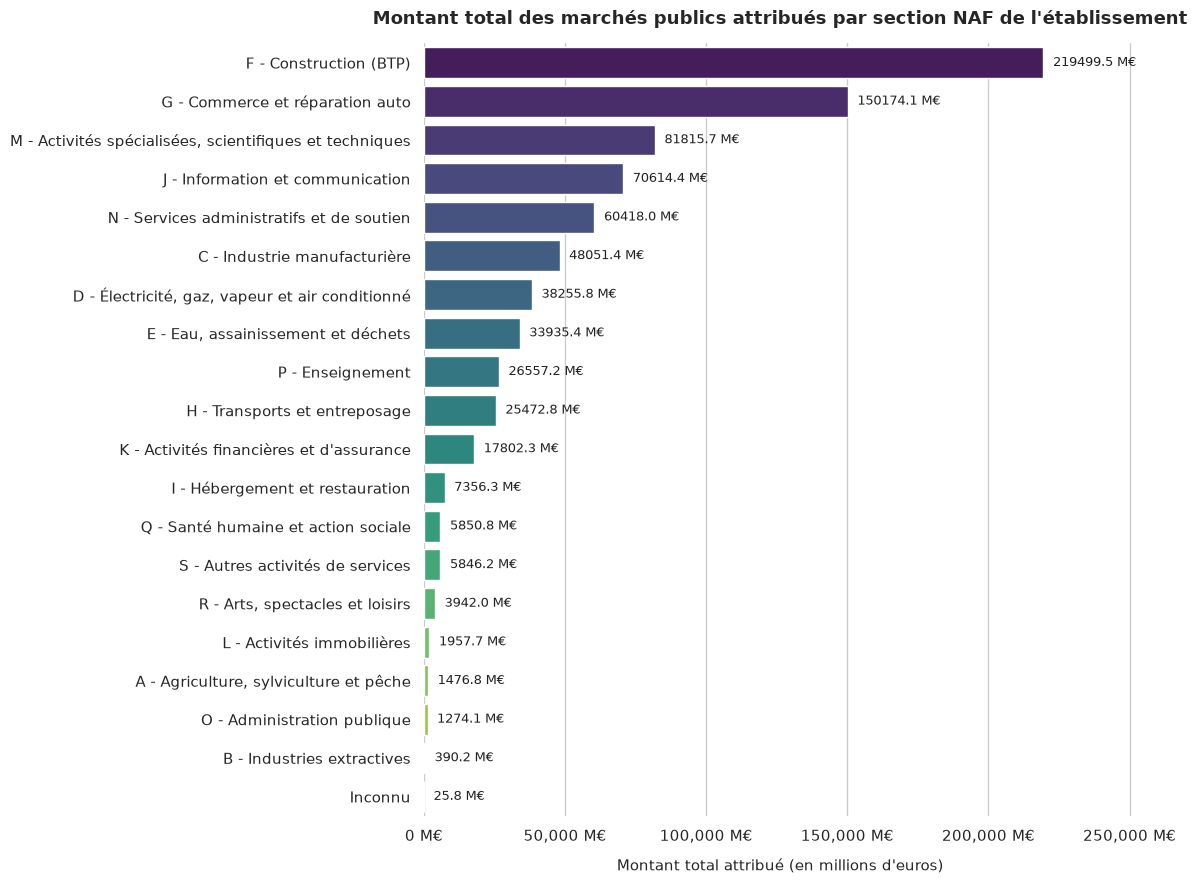

In [7]:
# Graphique 1 : Volume financier total attribué par section NAF (20 sections)
plot_montants_par_secteur(df_final)

Le verdict est sans appel : **la commande publique bénéficie de manière fortement disproportionnée à un noyau restreint de secteurs.** Les 10 premières sections NAF concentrent **94,3 %** des montants appariés (754,8 Md€ sur ~800,7 Md€) :

| Rang | Section NAF | Montant total (M€) | Part DECP (%) | Part Sirene (%) | Indice de surreprésentation | Contrats | Entreprises | Médiane (€) |
| :---: | :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| 1 | **F - Construction (BTP)** | 219 499,5 | 27,41 % | 6,08 % | **4,51** | 315 955 | 31 441 | 134 938 |
| 2 | **G - Commerce et réparation auto** | 150 174,1 | 18,76 % | 11,07 % | **1,69** | 111 106 | 11 720 | 100 500 |
| 3 | **M - Activités spécialisées, sc. et tech.** | 81 815,7 | 10,22 % | 9,35 % | **1,09** | 158 768 | 25 786 | 63 243 |
| 4 | **J - Information et communication** | 70 614,4 | 8,82 % | 2,95 % | **2,99** | 26 242 | 4 670 | 150 000 |
| 5 | **N - Services administratifs et de soutien** | 60 418,0 | 7,55 % | 5,78 % | **1,31** | 55 032 | 7 672 | 128 000 |
| 6 | **C - Industrie manufacturière** | 48 051,4 | 6,00 % | 2,82 % | **2,12** | 57 250 | 7 893 | 112 000 |
| 7 | **D - Électricité, gaz, vapeur et air cond.** | 38 255,8 | 4,78 % | 1,53 % | **3,13** | 9 915 | 288 | 420 000 |
| 8 | **E - Eau, assainissement et déchets** | 33 935,4 | 4,24 % | 0,28 % | **15,08** | 18 359 | 1 694 | 200 000 |
| 9 | **P - Enseignement** | 26 557,2 | 3,32 % | 3,23 % | **1,03** | 9 631 | 2 680 | 100 000 |
| 10 | **H - Transports et entreposage** | 25 472,8 | 3,18 % | 3,17 % | **1,00** | 16 178 | 2 685 | 200 000 |

Quatre enseignements ressortent nettement :

- **Domination massive du duo BTP–Commerce :** la **Construction (F)** capte à elle seule **219,5 Md€** (**27,41 %** de la dépense publique), devant le **Commerce (G)** avec **150,2 Md€** (**18,76 %**, achats de fournitures, matériels, équipements et véhicules). Ensemble, ces deux sections absorbent **46,2 %** des montants publics.
- **Surreprésentation record des secteurs de réseaux et d'infrastructures :** la section **E (Eau, assainissement et déchets)** atteint un indice exceptionnel de **15,08** (4,24 % des montants pour seulement 0,28 % des établissements actifs). Viennent ensuite la **Construction (4,51)**, l'**Énergie (3,13)**, l'**Information et communication (2,99)** et l'**Industrie manufacturière (2,12)**.
- **Oligopole dans l'énergie :** la section **D (Électricité, gaz, vapeur)** concentre **38,3 Md€** sur seulement **288 entreprises** distinctes.
- **Sous-représentation marquée de l'immobilier et équilibre dans certains services :** la section **L (Activités immobilières)**, 1re branche de France en nombre d'établissements actifs (23,52 %), n'apparaît même pas dans le Top 10. À l'inverse, les **Transports (1,00)**, l'**Enseignement (1,03)** et les **Activités spécialisées (1,09)** affichent un poids financier très proche de leur part démographique dans Sirene.

### B. Structure et dispersion des montants annualisés par grande branche

Pour comparer la taille unitaire des marchés indépendamment de leur durée, nous visualisons la distribution du **montant annualisé** sur les 10 sections les plus fréquentes en nombre de contrats, sous forme de boîtes à moustaches en échelle logarithmique (valeurs extrêmes masquées).

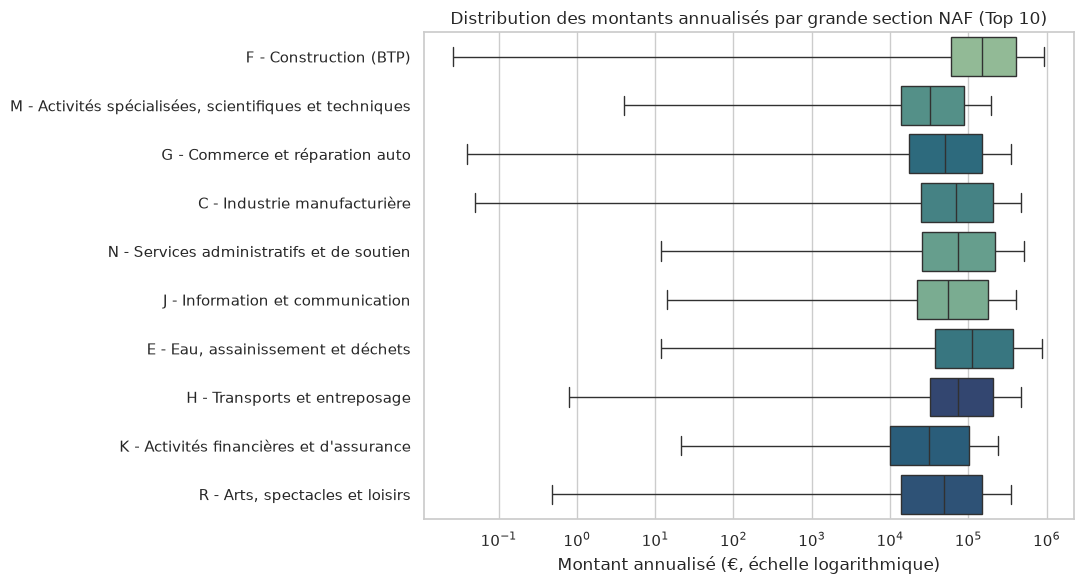

In [8]:
# Graphique 2 : Distribution des montants annualisés (Top 10 sections NAF)
plot_distribution_montants_annualises(df_final)

La lecture conjointe des boîtes à moustaches et des médianes brutes oppose deux logiques économiques :

- **Les branches de « gros contrats unitaires » :** l'**Électricité et gaz (D)** domine nettement avec une médiane de **420 000 €** par marché, suivie par l'**Eau, assainissement et déchets (E)** (**200 000 €**), les **Transports et entreposage (H)** (**200 000 €**) et l'**Information et communication (J)** (**150 000 €**).
- **Les branches de « volume et de granularité » :** les **Activités spécialisées, scientifiques et techniques (M)** — ingénierie, maîtrise d'œuvre, conseil, architecture — enregistrent **158 768 contrats** (2e rang en volume de contrats) mais présentent la médiane la plus faible du Top 10 (**63 243 €**). La **Construction (F)** combine un volume contractuel massif (**315 955 contrats**) et une médiane intermédiaire (**134 938 €**), reflétant la coexistence de nombreux chantiers communaux de proximité et de grands travaux d'infrastructures.

### C. Poids des entreprises selon la taille d'établissement

Au-delà de la spécialisation sectorielle, nous examinons comment se répartit la dépense publique selon la **taille salariale de l'établissement titulaire** (regroupement des tranches d'effectifs Insee en 6 catégories standard : Micro 0–9 sal., Petite 10–49 sal., Moyenne 50–249 sal., ETI 250–4 999 sal., Grande Entreprise 5 000+ sal., et Non renseigné / 0 salarié). Le graphique confronte le **volume total capté** (panneau 1) à la **distribution des montants unitaires** en échelle logarithmique (panneau 2).

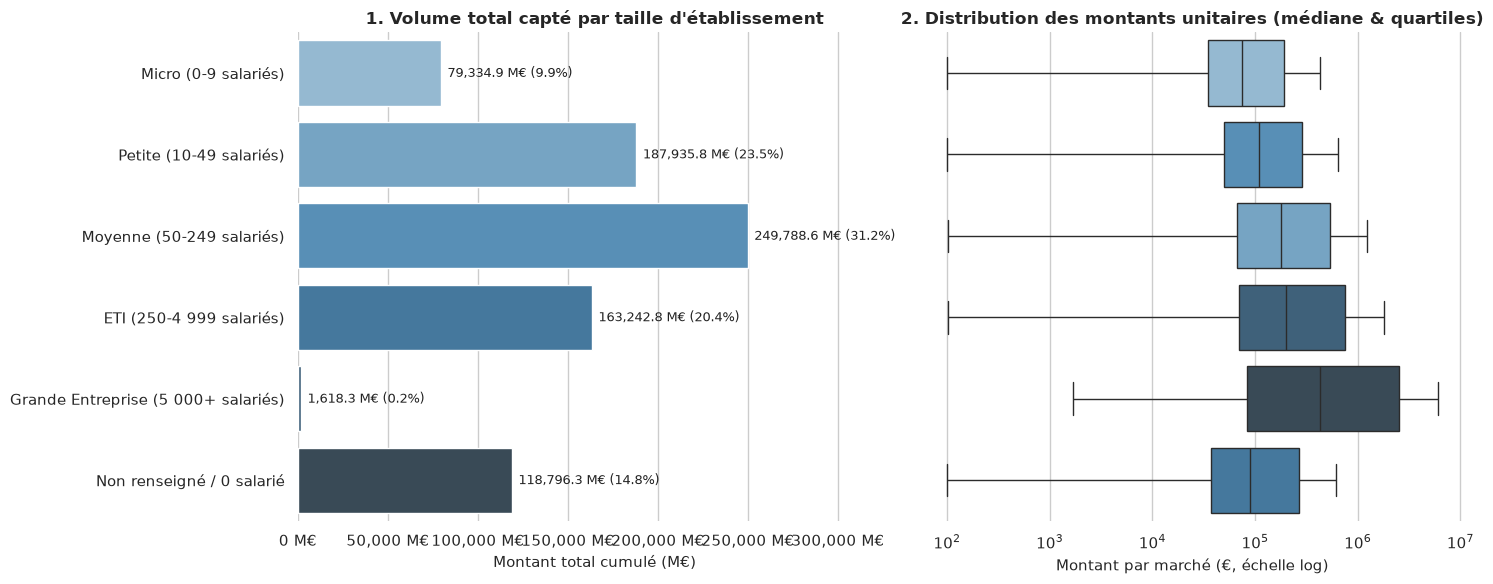

In [9]:
# Graphique 3 : Volume total et distribution unitaire par taille d'établissement
plot_repartition_taille_etablissement(df_final)

Cette double visualisation met en évidence un résultat central sur l'accès au marché public :

- **Le tissu des PME (Petites et Moyennes structures) et des ETI constitue le cœur financier de la commande publique** en volume agrégé, tandis que les très grands établissements (5 000+ salariés) restent numériquement rares au niveau « établissement » dans Sirene (beaucoup de grands groupes répondant via des filiales ou agences de taille intermédiaire).
- **Une hiérarchie nette des montants unitaires selon la taille :** sur le panneau de droite (échelle logarithmique), la médiane et l'intervalle interquartile des montants par contrat progressent régulièrement des **Micro-établissements (0–9 salariés)** vers les **Petites**, **Moyennes**, **ETI** et **Grandes Entreprises**, illustrant l'effet de capacité financière et opérationnelle requis pour remporter les marchés les plus importants.
- **Un point de vigilance sur la catégorie `Non renseigné / 0 salarié` (`NN`) :** son poids non négligeable rappelle que le code effectif dans Sirene peut être absent pour des établissements nouvellement créés, des sociétés holdings ou certaines entités sans salarié direct, et qu'il mesure l'effectif de l'**établissement** (SIRET) plutôt que celui du groupe consolidé.

### D. Procédures de passation et accès des différentes tailles d'entreprises

Pour relier les règles juridiques de la commande publique à la structure des lauréats, nous analysons d'abord le **poids financier de chaque procédure de passation** (Graphique 4), puis croisons **procédure × taille d'établissement** en comparant la répartition en **nombre de marchés** et en **volume d'euros** (Graphique 5).

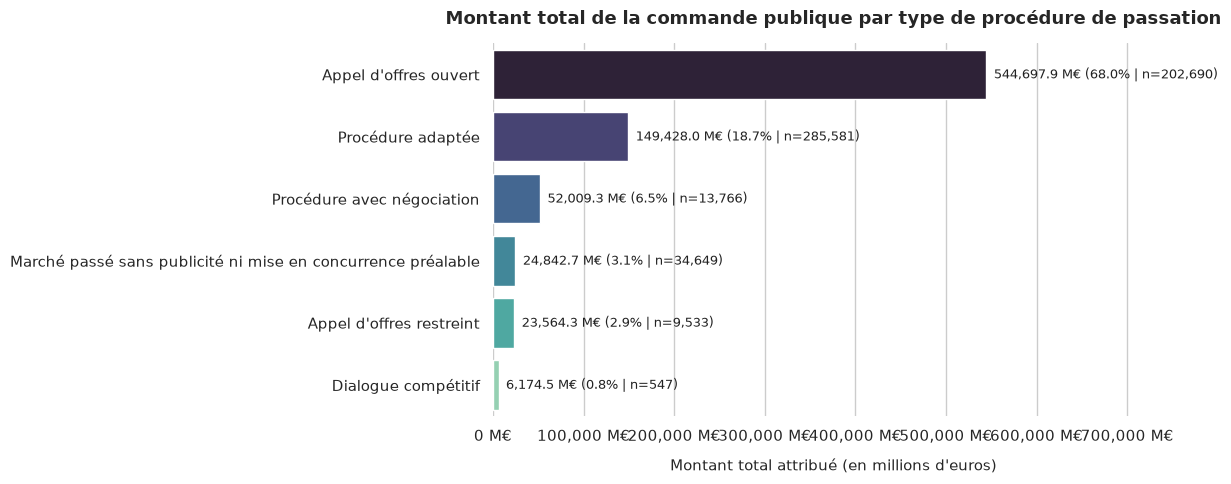

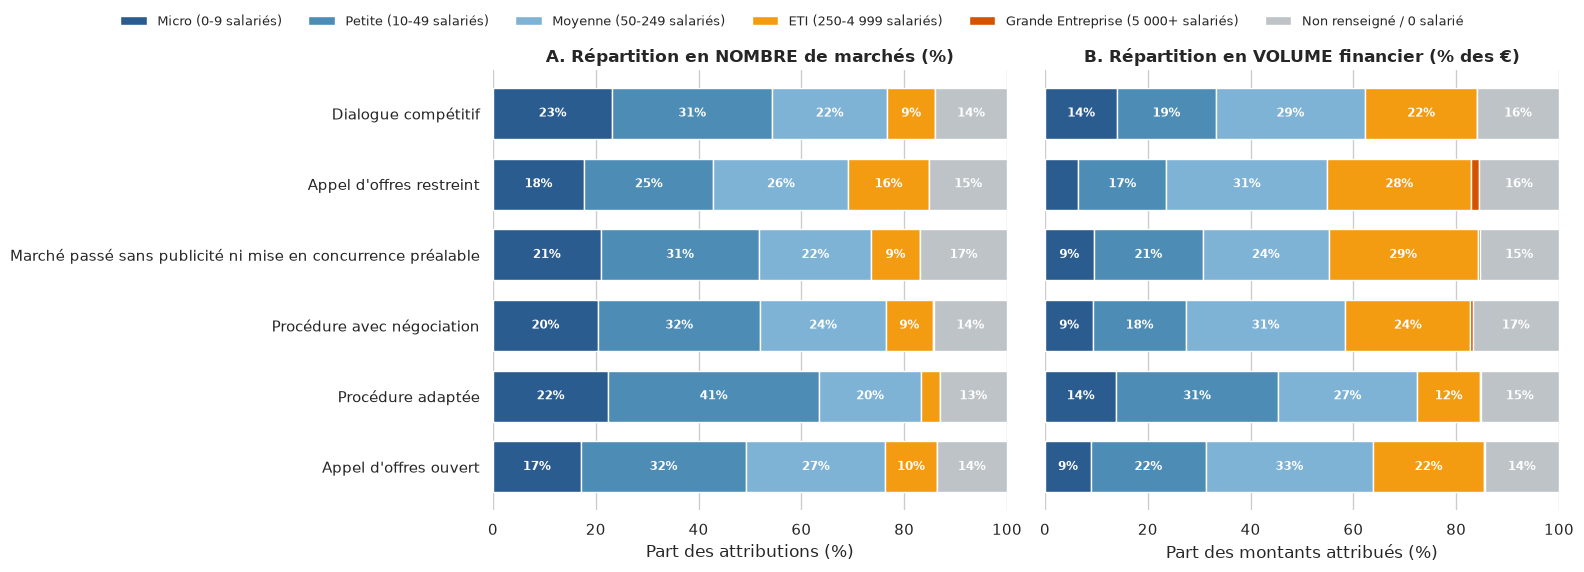

In [10]:
# Graphique 4 : Montant total attribué par type de procédure de passation
plot_montants_par_procedure(df_final)

# Graphique 5 : Croisement Procédure x Taille (A. Nombre de marchés vs B. Volume en euros)
plot_procedure_par_taille(df_final)

L'articulation de ces deux graphiques éclaire directement le mécanisme de sélection par les seuils européens :

- **Une bipolarisation autour de deux procédures phares :** l'**Appel d'offres ouvert** (procédure formalisée au-dessus des seuils européens) et la **Procédure adaptée (MAPA)** (procédure allégée sous les seuils) concentrent l'essentiel des montants et du nombre d'attributions, devant les procédures avec négociation, les appels d'offres restreints et les marchés sans publicité ni mise en concurrence.
- **Un décalage systématique entre « nombre de contrats » et « volume en euros » :** dans le Graphique 5, la comparaison entre le panneau A (part des attributions) et le panneau B (part des montants) montre que les **Micro et Petites structures** remportent une proportion plus élevée du *nombre* de marchés — en particulier dans les procédures adaptées — mais une part plus réduite du *volume financier*, qui bascule davantage vers les **Moyennes entreprises et ETI** dans les procédures formalisées (appels d'offres ouverts/restreints et procédures négociées).

### E. Géographie départementale de la dépense publique

Enfin, une carte choroplèthe interactive à l'échelle départementale représente le montant total attribué (en M€) et le nombre de marchés distincts selon le **département d'implantation de l'établissement titulaire** (`dep_titulaire`).

In [11]:
# Graphique 6 : Cartographie départementale interactive des montants attribués
plot_carte_departements(df_final)

La cartographie fait apparaître une forte concentration territoriale en **Île-de-France** (Paris et Hauts-de-Seine en tête) et dans les grands départements métropolitains (Rhône, Nord, Bouches-du-Rhône, Haute-Garonne, Gironde, Loire-Atlantique), par contraste avec des volumes beaucoup plus modestes dans les départements ruraux.

Cette polarisation reflète toutefois deux phénomènes superposés : le poids démographique et économique des grandes métropoles, mais aussi un **effet de domiciliation juridique**, la carte localisant l'établissement titulaire issu de Sirene (`dep_titulaire`) et non le lieu d'exécution physique des prestations (`lieuExecution_code`).

## III. Approfondissement financier : dépendance des entreprises à la commande publique (INPI / BCE)

L'analyse précédente mesurait la dépense publique du point de vue de l'acheteur public (quels secteurs reçoivent le plus d'argent ?). Dans cette troisième partie, nous renversons la perspective en nous plaçant du côté des **entreprises titulaires** : quelle part de leur chiffre d'affaires annuel les marchés publics représentent-ils ?

### A. Agrégation par SIREN, appariement INPI et diagnostic de confidentialité

Les comptes annuels étant déposés au niveau de l'unité légale (entreprise mère), nous agrégeons d'abord `df_final` au niveau **SIREN (9 chiffres)** en calculant pour chaque entreprise son nombre de marchés, son nombre d'établissements gagnants, son montant cumulé, son montant annualisé total (`montant_annualise_total`) et son secteur NAF principal. Nous apparions ensuite cette table en jointure stricte `one_to_one` avec l'exercice comptable le plus récent disponible dans la base **INPI / BCE** (`ratios_inpi_bce`).

In [12]:
# Agrégation par SIREN, jointure INPI/BCE et diagnostic de complétude/confidentialité
from fonctions import (
    agreger_et_joindre_inpi,
    diagnostiquer_base_entreprises,
)

df_entreprise = agreger_et_joindre_inpi(df_final, URL_RATIOS_INPI)
diagnostiquer_base_entreprises(df_entreprise, url_inpi=URL_RATIOS_INPI)

Entreprises uniques (SIREN) dans DECP : 109,790
Entreprises présentes dans la base INPI : 70,876 (64.6%)
Entreprises avec chiffre d'affaires non confidentiel : 70,876 (64.6%)
=== DIAGNOSTIC DES VALEURS MANQUANTES (df_entreprise) ===
                                      nb_valeurs_presentes  nb_NaN  taux_NaN_pct   type_colonne
siren                                               109790       0           0.0            str
nb_marches                                          109790       0           0.0          int64
nb_etablissements_gagnants                          109790       0           0.0          int64
montant_total                                       109790       0           0.0        float64
montant_moyen                                       109790       0           0.0        float64
montant_median                                      109790       0           0.0        float64
montant_annualise_total                             109790       0           0.0        float64

L'appariement au niveau entreprise (`df_entreprise`) livre des enseignements importants sur la couverture des données comptables publiques en France :

- **Volume et taux d'appariement :** sur **109 790 entreprises uniques (SIREN)** titulaires d'au moins un marché public dans les DECP, **70 876 entreprises (64,6 %)** sont retrouvées dans la base des ratios INPI/BCE avec une date de clôture et un chiffre d'affaires renseignés. Les **38 914 entreprises non appariées (35,4 %)** correspondent notamment aux entrepreneurs individuels, associations, organismes publics ou sociétés n'ayant pas déposé de comptes exploitables.
- **Impact de la confidentialité des comptes :** parmi les 70 876 entreprises appariées, **37 678** déposent des comptes intégralement **`Public`**, **29 583** optent pour un régime **`Partiellement confidentiel`** (compte de résultat confidentiel pour les petites entreprises), **3 358** sont en **`Partiellement confidentiel (RAPCAC)`** et **257** en **`Publication simplifiee`**.
- **Conséquence sur les ratios exploitables :** si le bilan de base (`chiffre_d_affaires`, `ebe`, `resultat_net`, `taux_d_endettement`, `autonomie_financiere`) est présent pour 64,6 % de la base, les ratios d'exploitation fins (`marge_ebe`, `poids_bfr_exploitation_sur_ca`, `rotation_des_stocks_jours`) affichent environ **65 % de valeurs manquantes** (environ 38 300 entreprises renseignées), ce qui correspond exactement au périmètre des sociétés à comptes non confidentiels et chiffre d'affaires strictement positif.

### B. Montants publics rapportés au chiffre d'affaires : une dépendance élevée

Sur le sous-ensemble des entreprises disposant à la fois d'un **chiffre d'affaires strictement positif** et d'un **montant annualisé de marchés positif** (environ **38 250 entreprises**), nous calculons le **taux de dépendance à la commande publique** :

$$\text{Taux de dépendance (\%)} = \frac{\text{Montant annualisé total des marchés gagnés}}{\text{Chiffre d'affaires annuel}} \times 100$$

Le nuage de points en échelle log-log compare ces deux grandeurs pour les 6 principales sections NAF, assorti de trois droites repères correspondant à **1 %**, **10 %** et **100 %** du chiffre d'affaires.

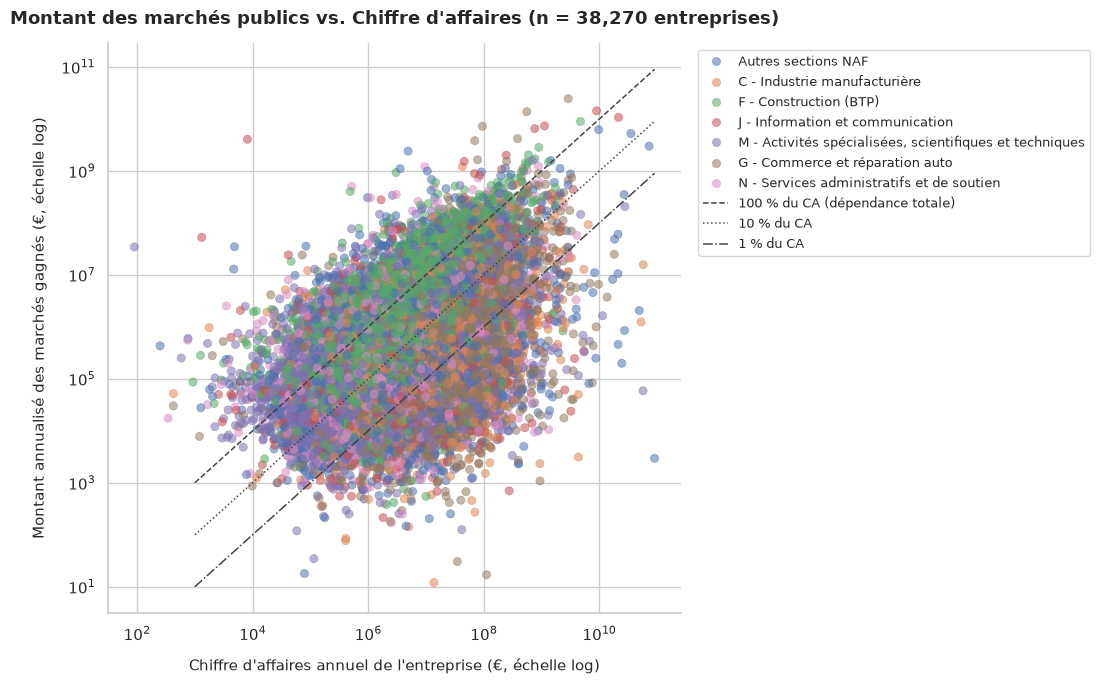

Médiane du ratio (Montant annualisé / CA) : 18.38 %
Part des entreprises réalisant > 10 % de leur CA via la commande publique : 60.5%


In [13]:
# Graphique 7 : Nuage de points log-log (Montant annualisé des marchés vs Chiffre d'affaires)
from fonctions import plot_dependance_loglog

plot_dependance_loglog(df_entreprise)

Les indicateurs issus de ce croisement mettent en évidence le rôle économique majeur de la commande publique pour les entreprises qui y participent :

- **Médiane du ratio `Montant annualisé / Chiffre d'affaires` : 18,38 %.** Pour la moitié des entreprises titulaires observables, les marchés publics représentent près d'un cinquième (ou davantage) de leur chiffre d'affaires annuel.
- **Part des entreprises dépassant 10 % de leur CA via la commande publique : 60,5 %.** La commande publique n'est donc pas un débouché marginal ou occasionnel pour les titulaires, mais un pilier structurant de leur activité.
- **Une relation fortement croissante mais très dispersée :** le nuage de points suit logiquement la diagonale (les grandes entreprises en CA gagnent des volumes annualisés plus élevés), mais l'écart vertical à taille de CA donnée montre que certaines entreprises dépendent à moins de 1 % de l'acheteur public tandis que d'autres se situent au voisinage ou au-dessus de la ligne des 100 %.

### C. Profils de dépendance par secteur d'activité et précautions méthodologiques

Pour analyser comment cette dépendance varie d'un secteur à l'autre, nous découpons les **38 252 entreprises** observables (CA > 0, montant annualisé > 0, NAF renseigné) en trois tranches autour des seuils de **1 %** et **100 %** du chiffre d'affaires, et comparons les **effectifs bruts** et les **parts en pourcentage** par section NAF.

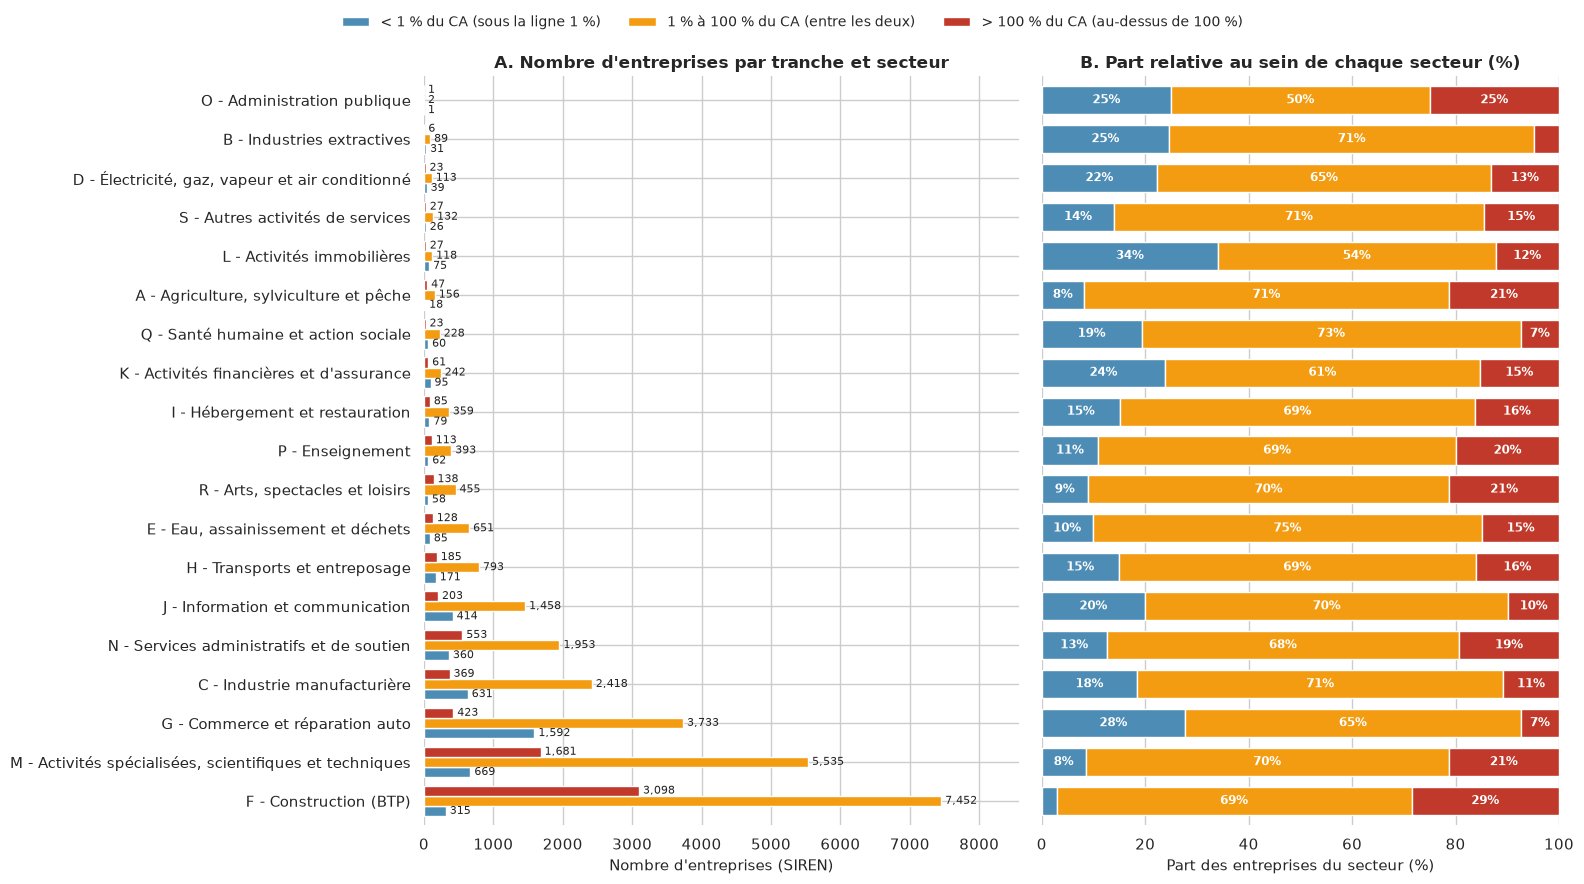

=== RÉPARTITION GLOBALE PAR TRANCHE DE DÉPENDANCE ===
                                    nb_entreprises  part_pct
tranche_dependance                                          
< 1 % du CA (sous la ligne 1 %)               4781      12.5
1 % à 100 % du CA (entre les deux)           26280      68.7
> 100 % du CA (au-dessus de 100 %)            7191      18.8


In [14]:
# Graphique 8 : Répartition par tranche de dépendance (< 1 %, 1-100 %, > 100 % du CA) par section NAF
from fonctions import plot_tranches_dependance_par_secteur

plot_tranches_dependance_par_secteur(df_entreprise)

Au niveau global, la répartition des **38 252 entreprises** par tranche de dépendance confirme le poids central de la commande publique :

| Tranche de dépendance (`Montant annualisé / CA`) | Nombre d'entreprises | Part (%) |
| :--- | :---: | :---: |
| **< 1 % du CA** (exposition marginale) | 4 781 | **12,5 %** |
| **1 % à 100 % du CA** (dépendance modérée à forte) | 26 280 | **68,7 %** |
| **> 100 % du CA** (montant annualisé supérieur au dernier CA connu) | 7 191 | **18,8 %** |
| **Total analysé** | **38 252** | **100,0 %** |

Plus de deux tiers des entreprises (**68,7 %**) se situent dans la bande cohérente entre 1 % et 100 % de leur chiffre d'affaires, tandis que seulement **12,5 %** ont une exposition inférieure à 1 %. Le graphique par section NAF met en outre en évidence le poids massif en nombre d'entreprises dépendantes dans la **Construction (F)**, les **Activités spécialisées (M)** et le **Commerce (G)**.

L'existence de **18,8 % d'entreprises au-dessus du seuil de 100 % du CA** (7 191 sociétés) ne signifie pas nécessairement une anomalie comptable, mais appelle **trois précautions d'interprétation essentielles** :

1. **Effet « plafond d'accord-cadre » :** dans les DECP, les accords-cadres à bons de commande sont déclarés pour leur montant *maximal* autorisé, qui est rarement consommé à 100 % dans la réalité — ce qui gonfle mécaniquement le numérateur `montant_annualise_total`.
2. **Décalage temporel et croissance rapide :** le dernier exercice disponible dans la base INPI/BCE peut précéder de 1 à 3 ans les marchés notifiés en 2024–2026 ; une entreprise jeune ou en forte croissance peut donc remporter des marchés supérieurs à son dernier CA publié.
3. **Sous-traitance et co-traitance :** les montants déclarés en DECP intègrent la part éventuellement sous-traitée, et les groupements sont divisés à parts égales faute de clé contractuelle dans les données brutes.

## IV. Modélisation et pistes d'approfondissement (optionnel)

Dans le cadre de cette étude, la modélisation n'est pas une fin prédictive en soi mais un prolongement analytique permettant de démêler des effets corrélés entre eux (secteur NAF, taille d'établissement, procédure de passation, localisation et taille financière de l'entreprise).

Deux pistes économétriques directement exploitables à partir des tables `df_final` et `df_entreprise` se dégagent :

1. **Isoler l'effet propre du secteur sur le montant des marchés :** une régression linéaire en logarithme,
$$\log(\text{montant\_annualise}_i) = \beta_0 + \beta_{\text{NAF}} + \beta_{\text{taille}} + \beta_{\text{procedure}} + \beta_{\text{dep}} + \varepsilon_i$$
permettrait de distinguer, « toutes choses égales par ailleurs », ce qui relève de la nature intrinsèque d'un secteur (ex. Énergie ou Eau) de ce qui provient simplement de la taille des entreprises titulaires ou du recours à l'appel d'offres ouvert.
2. **Relier dépendance à la commande publique et santé financière :** à partir de `df_entreprise` (où figurent déjà `marge_ebe`, `taux_d_endettement`, `autonomie_financiere` et `credit_clients_jours`), on pourrait tester si les entreprises fortement dépendantes de l'acheteur public affichent, à secteur et chiffre d'affaires comparables, une rentabilité plus stable, un endettement moindre ou des délais de paiement clients spécifiques.

## Conclusion

Nous avons construit ce projet pour répondre de façon empirique et reproductible à une question centrale d'économie publique : **qui bénéficie réellement de la commande publique française, et dans quelle mesure les entreprises titulaires en dépendent-elles ?** En consolidant **923 514 lignes brutes** des DECP (2024–2026), en les nettoyant jusqu'à obtenir **841 697 contrats × titulaires** appariés à **99,7 % en lignes (99,6 % en montant)** au répertoire **Sirene** (44,5 millions d'établissements), puis en croisant les **109 790 entreprises uniques (SIREN)** avec les comptes annuels **INPI / BCE** (**70 876 entreprises appariées**, soit **64,6 %**), nous avons pu dresser un portrait complet de la dépense publique.

Nos analyses apportent trois réponses claires à la problématique :

1. **Une surreprésentation sectorielle massive :** sur les ~**800,7 milliards d'euros** appariés, **94,3 %** des montants se concentrent sur 10 sections NAF et **46,2 %** sur le seul duo **Construction (27,41 %, indice 4,51)** – **Commerce (18,76 %, indice 1,69)**. Les déséquilibres les plus spectaculaires touchent les infrastructures et réseaux, notamment l'**Eau, assainissement et déchets (indice 15,08)** et l'**Électricité et gaz (indice 3,13**, concentrés sur **288 entreprises** avec une médiane de **420 000 €**), alors que l'**Immobilier** (23,52 % des établissements actifs en France) reste marginal.
2. **Une structuration nette par taille et par procédure :** si les petites structures remportent une part importante du *nombre* de marchés (notamment en procédure adaptée), les volumes financiers basculent nettement vers les établissements moyens et les ETI dans les procédures formalisées, avec une progression régulière des montants unitaires selon la taille salariale.
3. **Une dépendance financière élevée des titulaires :** parmi les **38 252 entreprises** à chiffre d'affaires public positif, la **médiane du ratio `montant annualisé / CA` atteint 18,38 %**, et **60,5 %** des entreprises réalisent plus de **10 %** de leur chiffre d'affaires via la commande publique (**68,7 %** se situent entre 1 % et 100 % du CA, et **18,8 %** dépassent même 100 % sous l'effet des plafonds d'accords-cadres et des décalages d'exercices).

Ces résultats s'accompagnent de limites méthodologiques clairement identifiées : filtrage des montants symboliques ($\le 100$ €) et extrêmes ($\ge 500$ M€), répartition égalitaire par défaut des groupements de co-titulaires, asymétrie liée aux plafonds d'accords-cadres non entièrement consommés, confidentialité d'environ un tiers des bilans d'entreprises dans l'INPI/BCE, et écart potentiel entre le département juridique du titulaire (`dep_titulaire`) et le lieu réel d'exécution (`lieuExecution_code`).

Deux pistes prolongeraient naturellement ce travail : mesurer la part d'achats véritablement locaux en confrontant `dep_titulaire` et `lieuExecution_code`, et exploiter les ratios de rentabilité (`marge_ebe`) et de trésorerie (`credit_clients_jours`) déjà intégrés dans `df_entreprise` pour évaluer l'impact de la commande publique sur la solidité financière des PME françaises.